<a href="https://colab.research.google.com/github/rafaelbarrientos2107-a11y/AF3-Pendulo-Robot/blob/main/AF3_MSIMS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

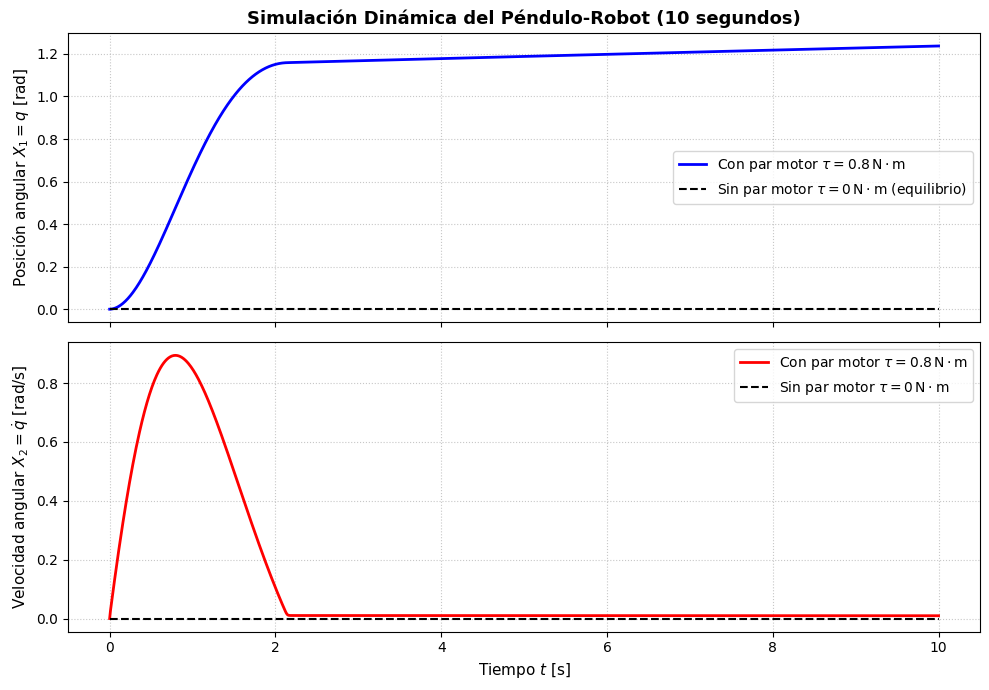

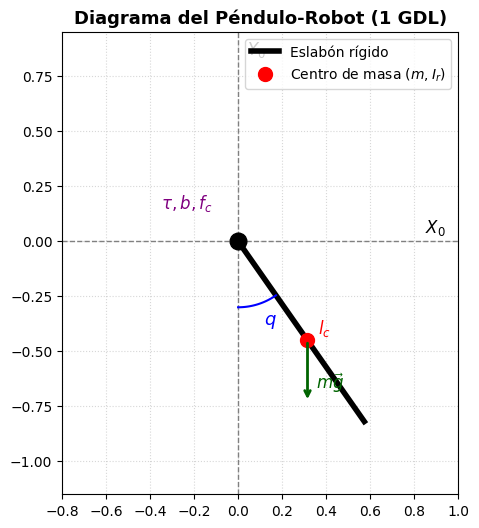

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==========================================
# 1. PARÁMETROS DEL SISTEMA PÉNDULO-ROBOT
# ==========================================
Ir = 0.16       # Momento de inercia [kg*m^2]
m = 5.0         # Masa total del mecanismo [kg]
g = 9.81        # Gravedad [m/s^2]
lc = 0.01       # Distancia al centro de masa [m]
b = 0.14        # Coeficiente de fricción viscosa [N*m*s/rad]
fc = 0.45       # Coeficiente de fricción de Coulomb [N*m]

J_total = m * (lc ** 2) + Ir   # Inercia total efectiva = 0.1605 kg*m^2
G_const = m * g * lc           # Par gravitacional máximo = 0.4905 N*m

# ==========================================
# 2. MODELO EN ESPACIO DE ESTADOS
# ==========================================
def pendulo_robot(t, X, tau):
    """
    X[0] = X1 = q   (posición angular en rad)
    X[1] = X2 = dq  (velocidad angular en rad/s)
    tau  = Par aplicado por el motor [N*m]
    """
    x1, x2 = X

    # Regularización suave de sign(x2) mediante tanh(100*x2) para evitar
    # inestabilidad numérica (chattering) en el cruce por velocidad cero.
    friccion_coulomb = fc * np.tanh(100.0 * x2)

    dx1 = x2
    dx2 = (1.0 / J_total) * (tau - b * x2 - friccion_coulomb - G_const * np.sin(x1))

    return [dx1, dx2]

# ==========================================
# 3. CONDICIONES INICIALES Y SIMULACIÓN (10 s)
# ==========================================
X0 = [0.0, 0.0]          # Condiciones iniciales: X1(0) = 0, X2(0) = 0
t_span = (0.0, 10.0)     # Tiempo total de simulación: 10 segundos
t_eval = np.linspace(0.0, 10.0, 1000)

# Caso A: Par escalón aplicado por el motor (tau = 0.8 N*m > fc = 0.45 N*m)
tau_aplicado = 0.8
sol_activa = solve_ivp(
    pendulo_robot, t_span, X0, args=(tau_aplicado,),
    t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-10
)

# Caso B: Entrada nula / respuesta libre en equilibrio (tau = 0.0 N*m)
sol_libre = solve_ivp(
    pendulo_robot, t_span, X0, args=(0.0,),
    t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-10
)

# ==========================================
# 4. GRÁFICAS DE POSICIÓN Y VELOCIDAD
# ==========================================
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Gráfica de Posición Angular X1(t) = q(t)
axs[0].plot(sol_activa.t, sol_activa.y[0], 'b-', linewidth=2,
            label=rf'Con par motor $\tau = {tau_aplicado}\,\mathrm{{N\cdot m}}$')
axs[0].plot(sol_libre.t, sol_libre.y[0], 'k--', linewidth=1.5,
            label=r'Sin par motor $\tau = 0\,\mathrm{N\cdot m}$ (equilibrio)')
axs[0].set_ylabel(r'Posición angular $X_1 = q$ [rad]', fontsize=11)
axs[0].set_title('Simulación Dinámica del Péndulo-Robot (10 segundos)', fontsize=13, fontweight='bold')
axs[0].grid(True, linestyle=':', alpha=0.7)
axs[0].legend(loc='best')

# Gráfica de Velocidad Angular X2(t) = dq/dt
axs[1].plot(sol_activa.t, sol_activa.y[1], 'r-', linewidth=2,
            label=rf'Con par motor $\tau = {tau_aplicado}\,\mathrm{{N\cdot m}}$')
axs[1].plot(sol_libre.t, sol_libre.y[1], 'k--', linewidth=1.5,
            label=r'Sin par motor $\tau = 0\,\mathrm{N\cdot m}$')
axs[1].set_xlabel('Tiempo $t$ [s]', fontsize=11)
axs[1].set_ylabel(r'Velocidad angular $X_2 = \dot{q}$ [rad/s]', fontsize=11)
axs[1].grid(True, linestyle=':', alpha=0.7)
axs[1].legend(loc='best')

plt.tight_layout()
plt.savefig('simulacion_pendulo_robot.png', dpi=300)
plt.show()

# ==========================================
# 5. GENERACIÓN DEL DIAGRAMA ESQUEMÁTICO
# ==========================================
fig_d, ax = plt.subplots(figsize=(6, 6))
q_demo = np.deg2rad(35)
L = 1.0
Lc = 0.55

# Ejes de referencia
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.axvline(0, color='gray', linestyle='--', linewidth=1)
ax.text(0.85, 0.04, r'$X_0$', fontsize=12, fontweight='bold')
ax.text(0.04, 0.85, r'$Y_0$', fontsize=12, fontweight='bold')

# Eslabón del péndulo
x_end, y_end = L * np.sin(q_demo), -L * np.cos(q_demo)
x_cm, y_cm = Lc * np.sin(q_demo), -Lc * np.cos(q_demo)
ax.plot([0, x_end], [0, y_end], 'k-', linewidth=4, label='Eslabón rígido')
ax.plot(0, 0, 'ko', markersize=12)
ax.plot(x_cm, y_cm, 'ro', markersize=10, label=r'Centro de masa ($m, I_r$)')

# Arco del ángulo q
theta_arc = np.linspace(-np.pi/2, -np.pi/2 + q_demo, 50)
ax.plot(0.3 * np.cos(theta_arc), 0.3 * np.sin(theta_arc), 'b-', linewidth=1.5)
ax.text(0.12, -0.38, r'$q$', fontsize=13, color='blue', fontweight='bold')

# Vector gravedad y anotaciones
ax.annotate('', xy=(x_cm, y_cm - 0.28), xytext=(x_cm, y_cm),
            arrowprops=dict(arrowstyle='->', color='darkgreen', lw=2))
ax.text(x_cm + 0.04, y_cm - 0.22, r'$m\vec{g}$', fontsize=12, color='darkgreen')
ax.text(x_cm + 0.05, y_cm + 0.03, r'$l_c$', fontsize=12, color='red')
ax.text(-0.35, 0.15, r'$\tau, b, f_c$', fontsize=12, color='purple', fontweight='bold')

ax.set_xlim(-0.8, 1.0)
ax.set_ylim(-1.15, 0.95)
ax.set_aspect('equal')
ax.set_title('Diagrama del Péndulo-Robot (1 GDL)', fontsize=13, fontweight='bold')
ax.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.5)
plt.savefig('diagrama_pendulo_robot.png', dpi=300)
plt.show()